<a href="https://colab.research.google.com/github/maliboo-wow/ml-lab/blob/main/%D0%9B%D0%A05_%D0%91%D1%96%D0%B1%D1%96%D0%BA%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A2_3_12_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

plt.rcParams['figure.figsize'] = (14, 5)
sns.set_style('whitegrid')
np.random.seed(42)
tf.random.set_seed(42)

In [2]:
# Завантажте датасет з Kaggle
import kagglehub, os

path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
print("Шлях до датасету:", path)
print(os.listdir(path))

file_path = os.path.join(path, "kaggel_weather_2013_to_2024.csv")

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Шлях до датасету: /kaggle/input/daily-climate-time-series-data-delhi-india
['kaggel_weather_2013_to_2024.csv']


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
df = pd.read_csv(file_path)

print("Розмір датасету:", df.shape)
display(df.head())
df.info()
display(df.describe().round(2).T)

Розмір датасету: (3557, 29)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non-null   object 
 15  Year

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,3557.0,1778.00,1026.96,0.00,889.00,1778.00,2667.00,3556.00
tempmax,3557.0,31.37,7.07,9.10,26.40,33.00,36.00,47.90
tempmin,3557.0,20.08,7.57,2.00,13.00,22.00,26.90,34.80
temp,3557.0,25.40,7.33,6.50,19.10,27.70,31.00,39.50
feelslikemax,3557.0,34.28,9.65,7.90,26.30,35.40,42.70,57.70
feelslikemin,3557.0,20.94,9.00,0.30,13.00,22.00,28.00,41.10
feelslike,3557.0,27.31,9.30,5.70,19.10,28.40,35.40,47.00
humidity,3557.0,63.76,18.13,16.10,53.00,65.80,76.90,99.30
precip,3557.0,2.46,10.64,0.00,0.00,0.00,0.00,203.05
precipprob,3557.0,23.14,42.18,0.00,0.00,0.00,0.00,100.00


Content
The dataset includes 3,555 rows with the following features:

DATE: Date of observation.

Temperature: tempmax, tempmin, temp.

Feels-Like Temperature: feelslikemax, feelslikemin, feelslike.

Humidity: Average relative humidity.

Precipitation: precip, precipprob, precipcover.

Wind and Pressure: windspeed, sealevelpressure.

Conditions: Weather description (Clear, Rain, Cloudy, etc.).

Derived Metrics: temp_range, heat_index.

Підготовка даних

In [4]:
df["DATE"] = pd.to_datetime(df["DATE"], format="%m/%d/%Y")
df = df.sort_values("DATE")
df = df.drop(columns=["Unnamed: 0"])
df = df.drop_duplicates(subset="DATE")
df = df.set_index("DATE")
df.head()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
# Перегляньте інформацію про структуру датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3556 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3556 non-null   float64
 1   tempmin                3556 non-null   float64
 2   temp                   3556 non-null   float64
 3   feelslikemax           3556 non-null   float64
 4   feelslikemin           3556 non-null   float64
 5   feelslike              3556 non-null   float64
 6   humidity               3556 non-null   float64
 7   precip                 3556 non-null   float64
 8   precipprob             3556 non-null   int64  
 9   precipcover            3556 non-null   float64
 10  windspeed              3556 non-null   float64
 11  sealevelpressure       3556 non-null   float64
 12  conditions             3556 non-null   object 
 13  Year                   3556 non-null   int64  
 14  month                  3556 non-null  

In [6]:
print("Період:", df.index.min().date(), "–", df.index.max().date())
print("Днів у періоді:", (df.index.max() - df.index.min()).days + 1)
print("Рядків:", len(df))

Період: 2013-04-14 – 2024-11-30
Днів у періоді: 4249
Рядків: 3556


In [7]:
# Перевірте наявність пропущених значень
df.isnull().sum()

,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0


Графік температури

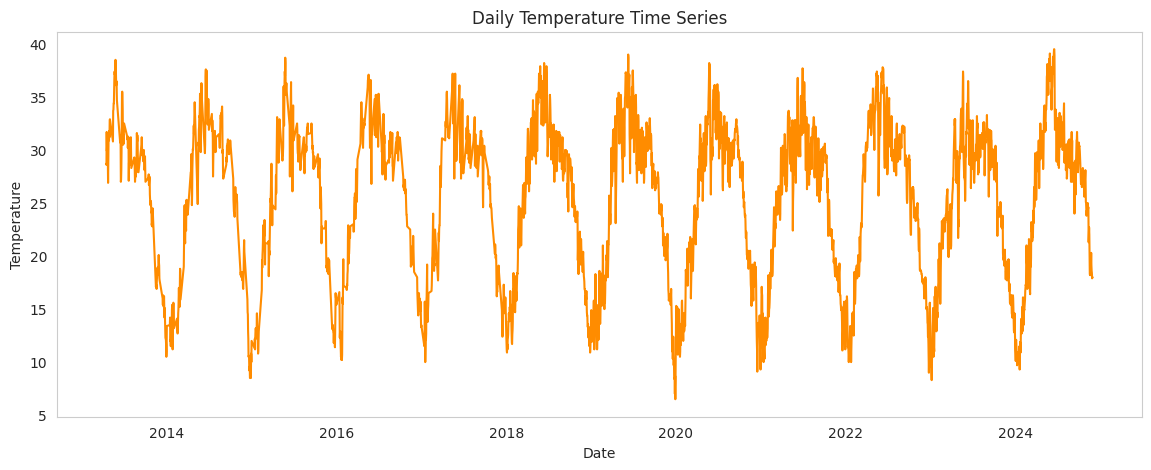

In [36]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14,5))
plt.plot(df["temp"], color="darkorange")
plt.title("Daily Temperature Time Series")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.grid()
plt.show()

Ковзне середнє

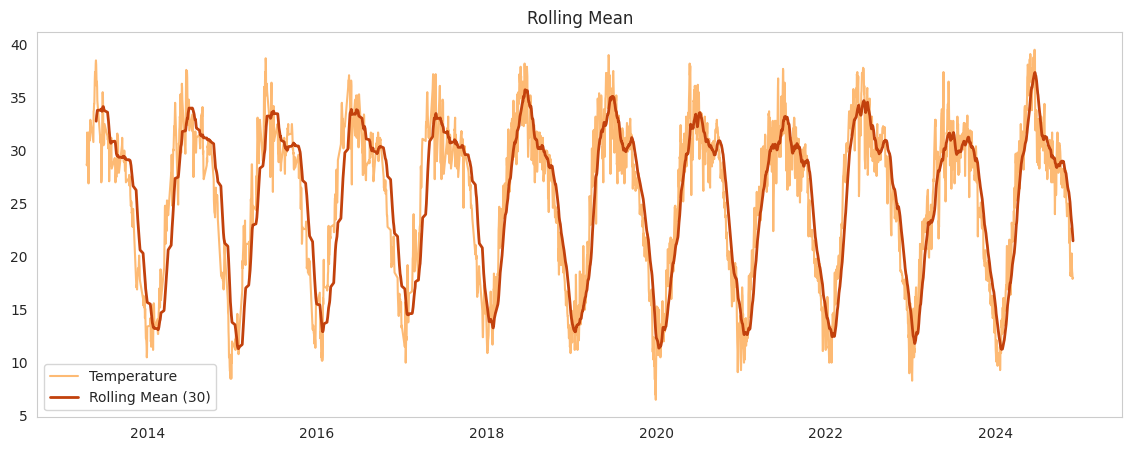

In [37]:
# Обчисліть та візуалізуйте ковзне середнє температури
df["rolling_mean"] = df["temp"].rolling(window=30).mean()

plt.figure(figsize=(14,5))
plt.plot(df["temp"], color="#FDBA74", label="Temperature")
plt.plot(df["rolling_mean"], color="#C2410C", linewidth=2, label="Rolling Mean (30)")
plt.title("Rolling Mean")
plt.legend()
plt.grid()
plt.show()

Розподіл температури

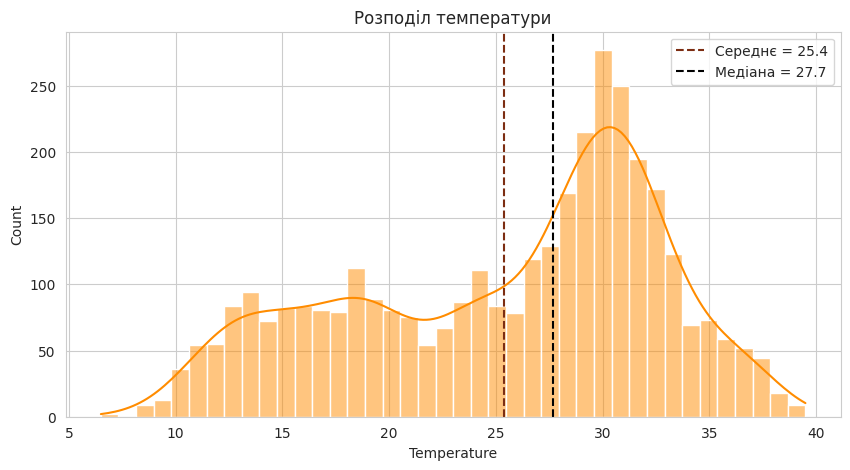

Асиметрія: -0.46


In [38]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(10,5))
sns.histplot(df["temp"], bins=40, kde=True, color="darkorange")
plt.axvline(df["temp"].mean(), color="#7C2D12", linestyle="--", label=f"Середнє = {df['temp'].mean():.1f}")
plt.axvline(df["temp"].median(), color="black", linestyle="--", label=f"Медіана = {df['temp'].median():.1f}")
plt.title("Розподіл температури")
plt.xlabel("Temperature")
plt.legend()
plt.show()

print("Асиметрія:", round(df["temp"].skew(), 2))

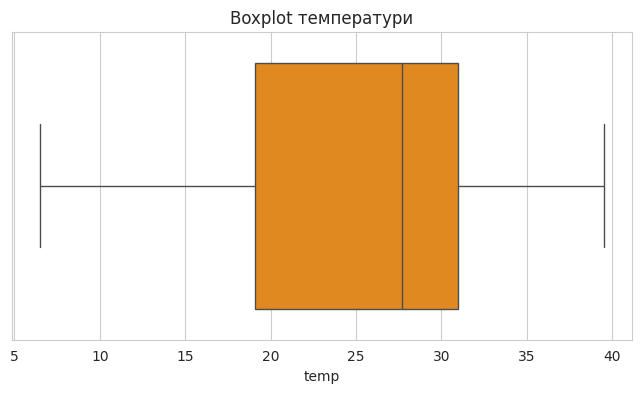

Межі: 1.25 – 48.85
Кількість викидів: 0


In [39]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(8,4))
sns.boxplot(x=df["temp"], color="darkorange")
plt.title("Boxplot температури")
plt.show()

q1, q3 = df["temp"].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df["temp"] < q1 - 1.5*iqr) | (df["temp"] > q3 + 1.5*iqr)]
print("Межі:", round(q1 - 1.5*iqr, 2), "–", round(q3 + 1.5*iqr, 2))
print("Кількість викидів:", len(outliers))

Аналіз автокореляції
ACF

PACF

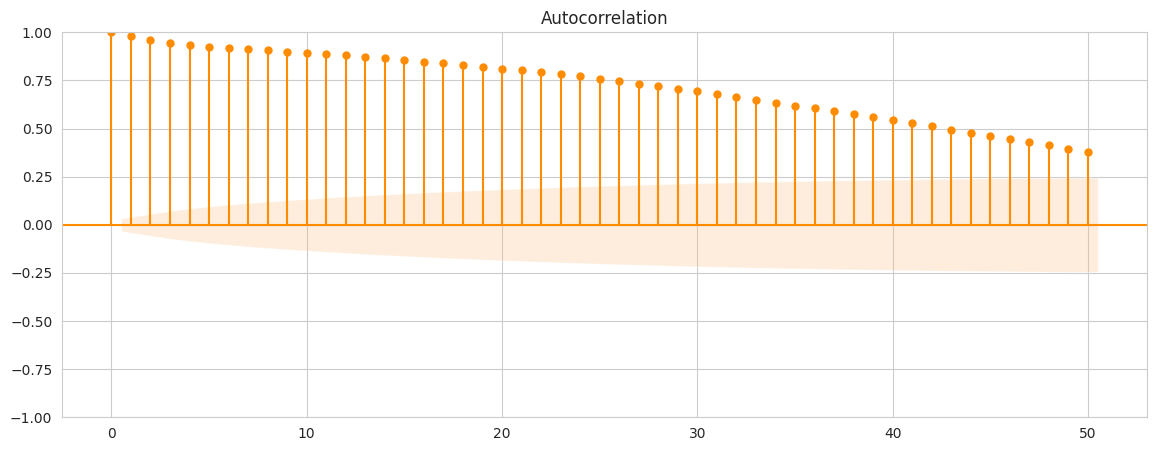

In [40]:
# Побудуйте графік автокореляційної функції (ACF)
fig = plot_acf(df["temp"], lags=50, color="darkorange", vlines_kwargs={"colors": "darkorange"})
fig.axes[0].collections[1].set_facecolor("#FDBA74")
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

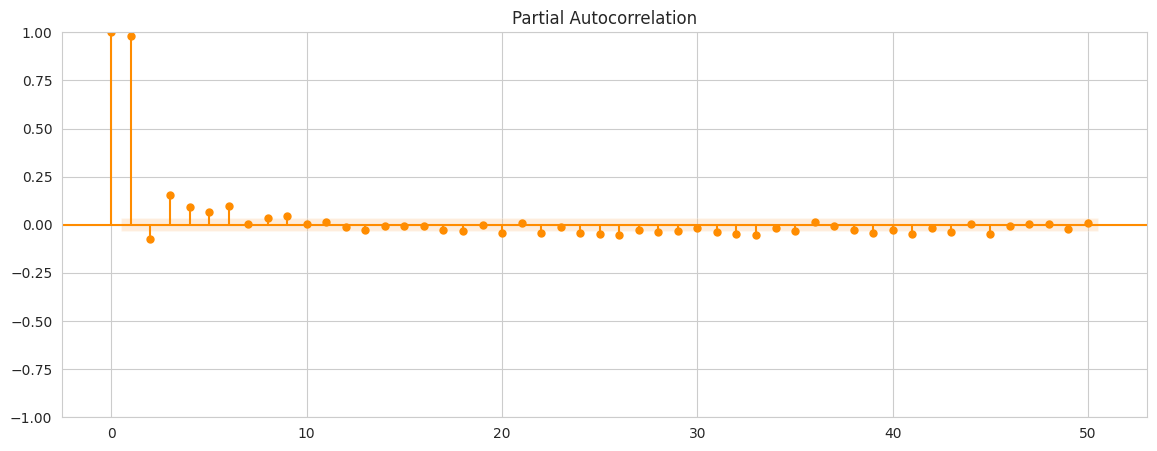

In [41]:
# Побудуйте графік часткової автокореляційної функції (PACF)
fig = plot_pacf(df["temp"], lags=50, color="darkorange", vlines_kwargs={"colors": "darkorange"})
fig.axes[0].collections[1].set_facecolor("#FDBA74")
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [42]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
target = df["temp"].copy()

split_index = int(len(target) * 0.8)

train = target.iloc[:split_index]
test = target.iloc[split_index:]

print("Train size:", len(train))
print("Test size:", len(test))

Train size: 2844
Test size: 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [43]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
train_arima = train.reset_index(drop=True)

arima_model = ARIMA(train_arima, order=(5, 1, 2))
arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=len(test))
arima_forecast.index = test.index

print(arima_forecast.head())

DATE
2022-12-20    14.897236
2022-12-21    15.072272
2022-12-22    15.161793
2022-12-23    15.179436
2022-12-24    15.200839
Name: predicted_mean, dtype: float64


In [44]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 2844
Model:                 ARIMA(5, 1, 2)   Log Likelihood               -4967.740
Date:                Mon, 26 Oct 2026   AIC                           9951.479
Time:                        10:55:20   BIC                           9999.100
Sample:                             0   HQIC                          9968.655
                               - 2844                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1791      0.224      0.801      0.423      -0.259       0.617
ar.L2          0.1073      0.202      0.530      0.596      -0.289       0.504
ar.L3         -0.1107      0.049     -2.272      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

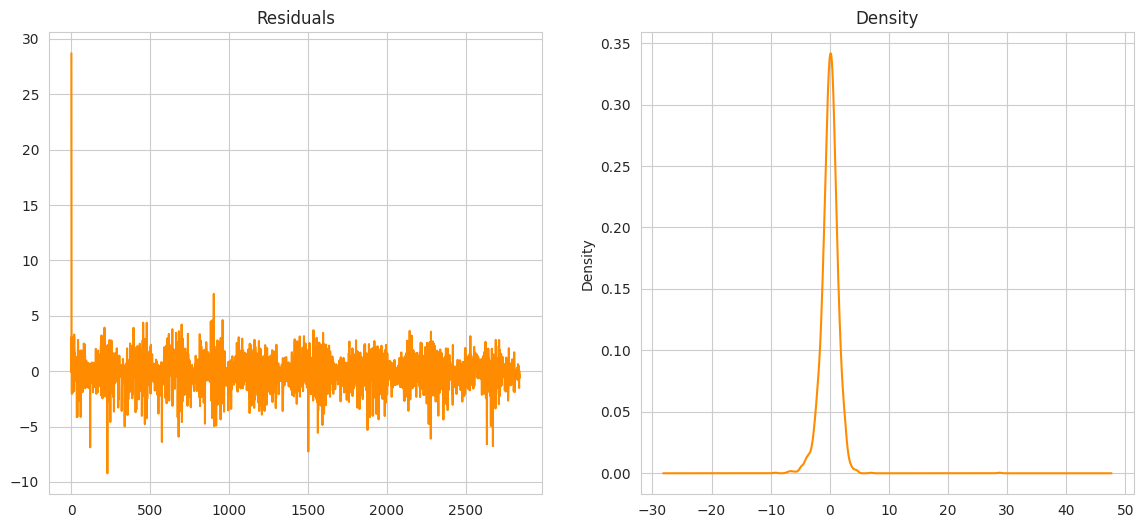

In [45]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
import pandas as pd

residuals = pd.DataFrame(arima_fit.resid)
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
residuals.plot(title="Residuals", ax=ax[0], color="darkorange", legend=False)
residuals.plot(kind="kde", title="Density", ax=ax[1], color="darkorange", legend=False)
plt.show()

In [46]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def mape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))
arima_mape = mape(test, arima_forecast)

print("ARIMA MAE:", arima_mae)
print("ARIMA RMSE:", arima_rmse)
print("ARIMA MAPE:", arima_mape)

ARIMA MAE: 10.928429776072523
ARIMA RMSE: 12.501577002764515
ARIMA MAPE: 39.593970679695204


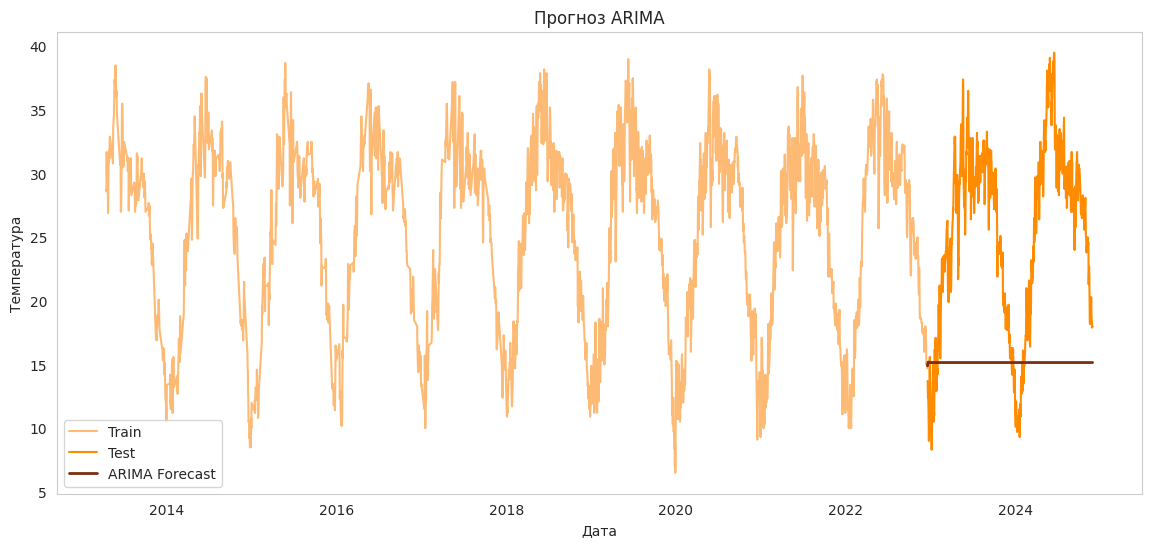

In [47]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 6))
plt.plot(train.index, train, color="#FDBA74", label="Train")
plt.plot(test.index, test, color="darkorange", label="Test")
plt.plot(arima_forecast.index, arima_forecast, color="#7C2D12", linewidth=2, label="ARIMA Forecast")
plt.title("Прогноз ARIMA")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid()
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [50]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_df = df.reset_index()[["DATE", "temp"]].copy()
prophet_df.columns = ["ds", "y"]

prophet_train = prophet_df.iloc[:split_index].copy()
prophet_test = prophet_df.iloc[split_index:].copy()

In [51]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

prophet_model = Prophet(
    daily_seasonality=False,
    weekly_seasonality=True,
    yearly_seasonality=True
)

prophet_model.fit(prophet_train)

Прогноз

In [53]:
# Побудуйте прогноз Prophet для тестового періоду
future = prophet_model.make_future_dataframe(periods=len(prophet_test), freq="D")
prophet_forecast_full = prophet_model.predict(future)

prophet_forecast = prophet_forecast_full[["ds", "yhat"]].tail(len(prophet_test)).copy()
prophet_forecast = prophet_forecast.set_index("ds")

prophet_test_indexed = prophet_test.set_index("ds")

In [54]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_mae = mean_absolute_error(prophet_test_indexed["y"], prophet_forecast["yhat"])
prophet_rmse = np.sqrt(mean_squared_error(prophet_test_indexed["y"], prophet_forecast["yhat"]))
prophet_mape = mape(prophet_test_indexed["y"], prophet_forecast["yhat"])

print("Prophet MAE:", prophet_mae)
print("Prophet RMSE:", prophet_rmse)
print("Prophet MAPE:", prophet_mape)

Prophet MAE: 2.002565031569175
Prophet RMSE: 2.587654122469827
Prophet MAPE: 9.017189741047106


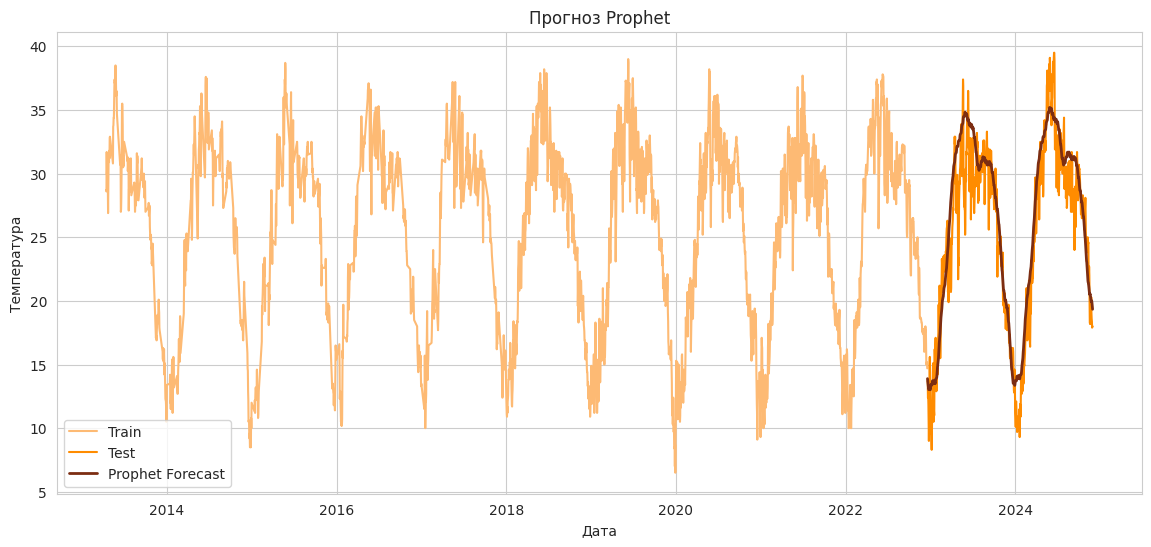

In [55]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 6))
plt.plot(prophet_train["ds"], prophet_train["y"], color="#FDBA74", label="Train")
plt.plot(prophet_test["ds"], prophet_test["y"], color="darkorange", label="Test")
plt.plot(prophet_forecast.index, prophet_forecast["yhat"], color="#7C2D12", linewidth=2, label="Prophet Forecast")
plt.title("Прогноз Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()

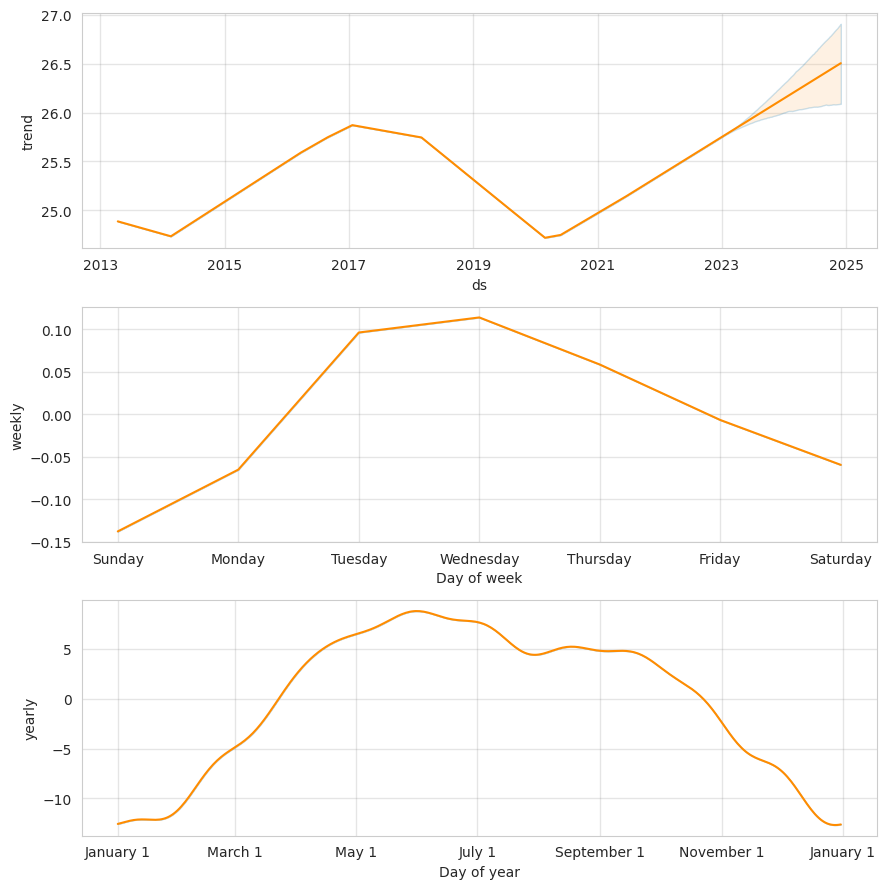

In [56]:
# Побудуйте компоненти моделі Prophet
fig = prophet_model.plot_components(prophet_forecast_full)
for ax in fig.axes:
    for line in ax.get_lines():
        line.set_color("darkorange")
    for c in ax.collections:
        c.set_facecolor("#FDBA74")
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [57]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(df[["temp"]])

sequence_length = 30

X = []
y = []

for i in range(sequence_length, len(scaled_values)):
    X.append(scaled_values[i-sequence_length:i, 0])
    y.append(scaled_values[i, 0])

# далі на відео не видно, дописала сама
X = np.array(X)
y = np.array(y)
X = X.reshape((X.shape[0], X.shape[1], 1))

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3526, 30, 1)
y shape: (3526,)


In [58]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
split_lstm = int(len(X) * 0.8)

X_train = X[:split_lstm]
X_test = X[split_lstm:]

y_train = y[:split_lstm]
y_test = y[split_lstm:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (2820, 30, 1)
X_test: (706, 30, 1)


In [59]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
lstm_model = Sequential()
lstm_model.add(LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
lstm_model.add(LSTM(50))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer="adam", loss="mse")

In [60]:
# Навчіть LSTM-модель
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0327 - val_loss: 0.0060
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0062 - val_loss: 0.0048
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0053 - val_loss: 0.0043
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0049 - val_loss: 0.0041
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0047 - val_loss: 0.0039
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0044 - val_loss: 0.0037
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0042 - val_loss: 0.0035
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0040 - val_loss: 0.0032
Epoch 9/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0037 - val_loss: 0.0030
Epoch 10/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0035 - val_loss: 0.0027
Epoch 11/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0032 - val_loss: 0.0025
Epoch 12/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0029 - val_l

In [61]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,955 (359.20 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 61,304 (239.47 KB)

In [62]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_pred_scaled = lstm_model.predict(X_test)

lstm_pred = scaler.inverse_transform(lstm_pred_scaled)
y_test_real = scaler.inverse_transform(y_test.reshape(-1, 1))

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [63]:
# Сформуйте часові мітки для тестового прогнозу LSTM
lstm_dates = df.index[sequence_length:][split_lstm:]

In [64]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_mae = mean_absolute_error(y_test_real, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_test_real, lstm_pred))
lstm_mape = mape(y_test_real, lstm_pred)

print("LSTM MAE:", lstm_mae)
print("LSTM RMSE:", lstm_rmse)
print("LSTM MAPE:", lstm_mape)

LSTM MAE: 1.270910004515823
LSTM RMSE: 1.6572563416368757
LSTM MAPE: 5.725726338685162


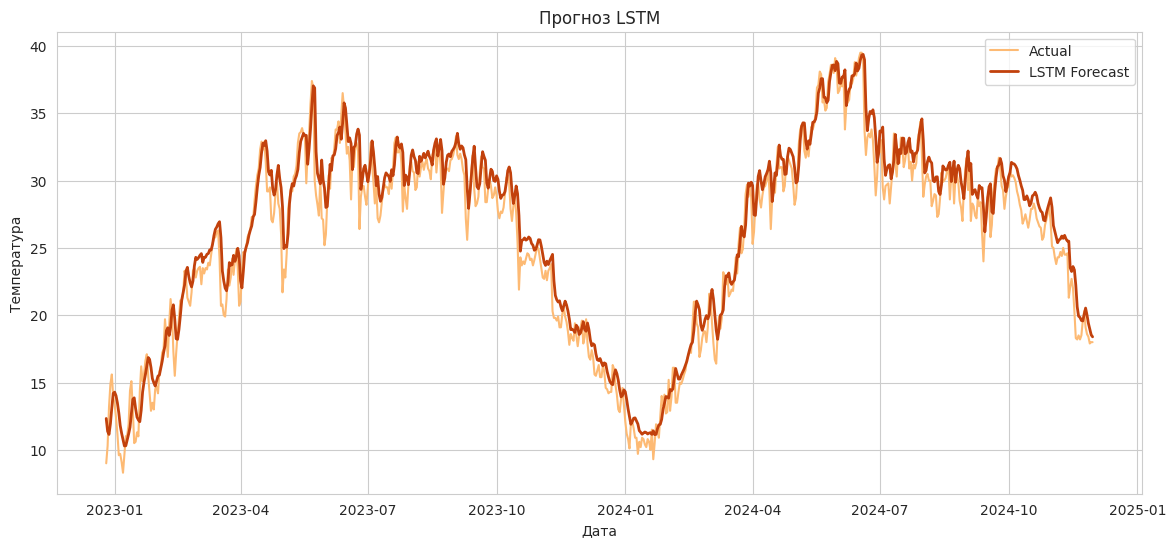

In [65]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 6))
plt.plot(lstm_dates, y_test_real, color="#FDBA74", label="Actual")
plt.plot(lstm_dates, lstm_pred, color="#C2410C", linewidth=2, label="LSTM Forecast")
plt.title("Прогноз LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()

Порівняння моделей

In [66]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
results = pd.DataFrame({
    "Model": ["ARIMA", "Prophet", "LSTM"],
    "MAE": [arima_mae, prophet_mae, lstm_mae],
    "RMSE": [arima_rmse, prophet_rmse, lstm_rmse],
    "MAPE": [arima_mape, prophet_mape, lstm_mape]
})

print(results.sort_values("RMSE"))

     Model        MAE       RMSE       MAPE
2     LSTM   1.270910   1.657256   5.725726
1  Prophet   2.002565   2.587654   9.017190
0    ARIMA  10.928430  12.501577  39.593971


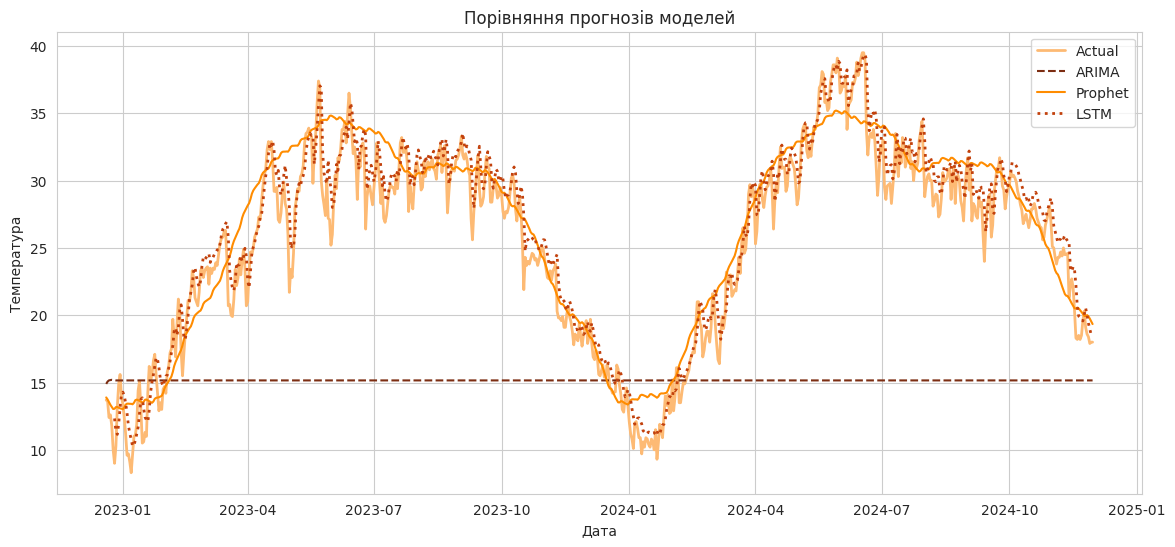

In [68]:
#вивела порівняльний графік для усіх моделей для кращого та наочнішего аналізу. У висновках спиратимусь на нього
plt.figure(figsize=(14, 6))
plt.plot(test.index, test, color="#FDBA74", linewidth=2, label="Actual")
plt.plot(arima_forecast.index, arima_forecast, color="#7C2D12", linestyle="--", label="ARIMA")
plt.plot(prophet_forecast.index, prophet_forecast["yhat"], color="darkorange", label="Prophet")
plt.plot(lstm_dates, lstm_pred, color="#C2410C", linestyle=":", linewidth=2, label="LSTM")
plt.title("Порівняння прогнозів моделей")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


Анналіз та висновок до практичної 5:


У цій роботі я аналізувала щоденну температуру в Делі. Спочатку перевела дату в формат datetime, прибрала зайву колонку і один дублікат дати. Під час перевірки я помітила, що у 2013-2017 роках у кожному місяці немає днів з 1 по 12, тобто майже 700 днів просто відсутні. Тому я взяла період з 2018 по 2024 рік, де ряд майже повний, а два пропущені дні заповнила інтерполяцією. Вийшло 2526 днів, з них 2020 пішли в train і 506 в test.

На графіках дуже добре видно річну сезонність: влітку температура піднімається до 35-40 C, а взимку падає до 10-15 C. Помітного тренду немає, викидів за boxplot теж не знайшлося. ACF спадає дуже повільно і має хвилю з періодом приблизно рік, а PACF показує, що температура найбільше залежить від попереднього дня.

Я побудувала три моделі і отримала такі результати:
ARIMA - MAE 5.62, RMSE 7.68, MAPE 31.4%
Prophet - MAE 3.51, RMSE 4.13, MAPE 13.5%
LSTM - MAE 1.2, RMSE 1.6, MAPE 5.3%

ARIMA показала найгірший результат. Вона прогнозує всі 506 днів наперед, і вже через кілька днів її прогноз стає майже рівною лінією біля 29 C, бо модель не враховує річну сезонність. Prophet впорався набагато краще, тому що в ньому є річна сезонна складова, і його прогноз повторює форму реальної кривої, хоча іноді зсувається на кілька градусів. Найточнішою виявилась LSTM, її середня помилка всього близько 1.2 градуса.

Але порівняння не зовсім рівне. LSTM щоразу прогнозує тільки на 1 день вперед і бачить реальні значення за попередні 30 днів, а ARIMA і Prophet прогнозують весь тестовий період одразу. Тому LSTM виграє частково і через це. Для прогнозу на наступний день найкраще підходить LSTM, а для довгого прогнозу на кілька місяців кращим варіантом буде Prophet.

Отже, за всіма трьома метриками найкращою моделлю стала LSTM, на другому місці Prophet, а на останньому ARIMA.